In [1]:
import os, sys, re, json, time, math, glob, random, zipfile, shutil, subprocess, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from tqdm.auto import tqdm
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tokenizers", "huggingface_hub", "scikit-learn"], check=False)

import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint
from torch.utils.data import DataLoader
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from tokenizers import Tokenizer

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WORK = "/kaggle/working"
RAW_DIR = "/kaggle/temp/hf_data"
OUT_DIR = f"{WORK}/rr_runs"
SUB_DIR = f"{WORK}/submissions_rr"
for d in (RAW_DIR, OUT_DIR, SUB_DIR): os.makedirs(d, exist_ok=True)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device: cuda Tesla T4


In [2]:
QUICK = False            # True = tiny smoke test (12 docs/split, 1 epoch)

MAX_LEN      = 1024      # chunk length (Phase 1 trained at 1024)
CTX_TOKENS   = 256       # left-context carried into each chunk (unscored)
MAX_SENT_TOK = 200       # truncate very long sentences
MICRO_BS, ACCUM = 4, 2   # doc-context mode
SENT_BS      = 32        # sentence-only mode
EVAL_BS, EVAL_SENT_BS = 8, 128
EPOCHS       = 4
HEAD_LR      = 1e-3
WD           = 0.01
WARMUP       = 0.06
USE_DOMAIN_TAG = True    # prepend "Corporate Law"/"Information Technology" to every chunk
CLASS_WEIGHT = True      # sqrt-inverse-frequency weighted CE
GRAD_CKPT    = False     # set True if you hit CUDA OOM
NB           = 20        # relative-position buckets
if QUICK: EPOCHS = 1

In [3]:
from huggingface_hub import login, snapshot_download
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
login(token=HF_TOKEN)
snapshot_download(repo_id="Exploration-Lab/CS-781-Capstone", repo_type="dataset",
                  local_dir=RAW_DIR, allow_patterns=["Phase_3_RR/*"])
P3 = os.path.join(RAW_DIR, "Phase_3_RR")
for dp, _, fns in os.walk(P3):
    for fn in sorted(fns):
        p = os.path.join(dp, fn); print(f"{os.path.getsize(p)/1e6:8.2f} MB  {p}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

    0.34 MB  /kaggle/temp/hf_data/Phase_3_RR/Train/CL_dev.json
    2.46 MB  /kaggle/temp/hf_data/Phase_3_RR/Train/CL_train.json
    0.17 MB  /kaggle/temp/hf_data/Phase_3_RR/Train/IT_dev.json
    1.51 MB  /kaggle/temp/hf_data/Phase_3_RR/Train/IT_train.json
    0.00 MB  /kaggle/temp/hf_data/Phase_3_RR/Train/label_vocab.json
    0.28 MB  /kaggle/temp/hf_data/Phase_3_RR/Test/CL_test.json
    0.19 MB  /kaggle/temp/hf_data/Phase_3_RR/Test/IT_test.json


In [4]:
def find_files(patterns, roots=("/kaggle/input", "/kaggle/working")):
    hits = []
    for r in roots:
        for p in patterns:
            hits += glob.glob(f"{r}/**/{p}", recursive=True)
    hits = [h for h in hits if "_last" not in os.path.basename(h) and "rr_runs" not in h]
    return sorted(set(hits))

tok_hits = find_files(["bpe32k.json"])
assert tok_hits, "bpe32k.json not found - attach your Phase 1 output as an input dataset"
TOK_PATH = tok_hits[0]
CKPTS = {}
for n in ["A_decoder", "B_encdec", "C_hybrid", "D_efficient"]:
    h = find_files([f"*{n}.pt"])
    assert h, f"checkpoint for {n} not found"
    CKPTS[n] = h[0]
print("tokenizer:", TOK_PATH)
for k, v in CKPTS.items(): print(f"{k:12s} {os.path.getsize(v)/1e6:7.1f} MB  {v}")

tok = Tokenizer.from_file(TOK_PATH)
SPECIAL = ["<pad>", "<unk>", "<bos>", "<eos>"]
PAD_ID, UNK_ID, BOS_ID, EOS_ID = [tok.token_to_id(s) for s in SPECIAL]
VOCAB_SIZE = tok.get_vocab_size()
print("vocab:", VOCAB_SIZE, "| ids:", PAD_ID, UNK_ID, BOS_ID, EOS_ID)

tokenizer: /kaggle/input/datasets/samswe/bpefile/bpe32k.json
A_decoder      268.2 MB  /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__A_decoder.pt
B_encdec       296.6 MB  /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__B_encdec.pt
C_hybrid       277.7 MB  /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__C_hybrid.pt
D_efficient    221.1 MB  /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__D_efficient.pt
vocab: 32000 | ids: 0 1 2 3


13 labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
first doc: {'id': 'CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733', 'domain': 'CL', 'text': ['Consequent upon the repeal of the MRTP Act this complaint has been received by transfer on 04.03.2010 from the office of DGIR, MRTP Commission under Section 66(6) of the Competition Act, 2002.', 'The facts as stated in the complaint, in brief, are: 2 .1 This complaint was filed by the All India Distillers Association against glass bottle manufacturers in India alleging restrictive and monopolistic trade practices being adopted by the four major manufacturers namely: Haldyn Glass Gujarat Limited, Hindustan National Glass and Industries, AGI Glasspac and Mohan Crystal Glass Work who together control 90 of the glass bottle market.'], 

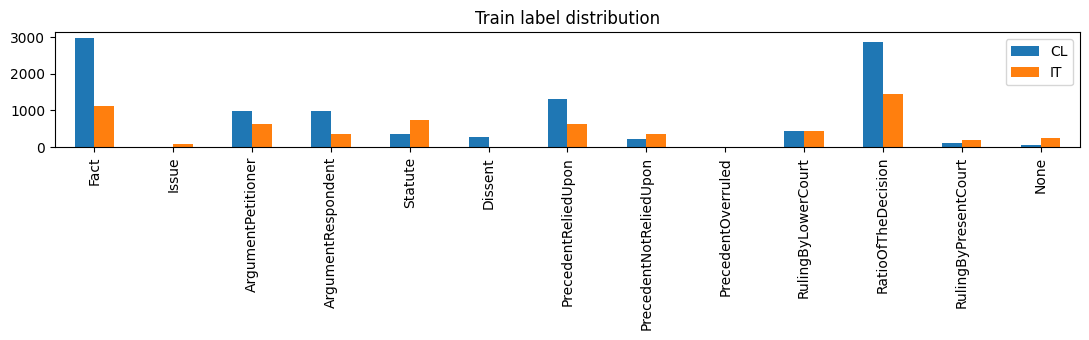

In [5]:
def load_json(p): return json.load(open(p, encoding="utf-8"))

def _get_text(v):
    if isinstance(v, str): return [v]
    if isinstance(v, list): return v
    if isinstance(v, dict):
        for k in ("text", "sentences", "sents", "sentence", "content", "document"):
            if k in v: return _get_text(v[k])
        for x in v.values():                                   # fallback: first list of strings
            if isinstance(x, list) and x and all(isinstance(s, str) for s in x): return x
    raise ValueError(f"cannot find sentence list in: {str(v)[:200]}")

def norm_docs(obj, domain):
    if isinstance(obj, dict):
        wrap = next((k for k in ("data", "documents", "docs") if k in obj and isinstance(obj[k], (list, dict))), None)
        if wrap: obj = obj[wrap]
    items = []
    if isinstance(obj, dict):                                  # {doc_id: value}
        for k, v in obj.items():
            lab = v.get("labels") if isinstance(v, dict) else None
            items.append((str(k), _get_text(v), lab))
    else:                                                      # [ {...}, ... ]
        for j, it in enumerate(obj):
            lab = it.get("labels") if isinstance(it, dict) else None
            did = it.get("id", j) if isinstance(it, dict) else j
            items.append((str(did), _get_text(it), lab))
    docs = []
    for did, text, lab in items:
        if lab is not None:
            lab = ["None" if y is None else y for y in lab]
            assert len(lab) == len(text), (did, len(lab), len(text))
        docs.append(dict(id=did, domain=domain, text=text, labels=lab))
    return docs

lv = load_json(f"{P3}/Train/label_vocab.json")
if isinstance(lv, dict):
    if all(isinstance(v, int) for v in lv.values()):
        LABELS = [k for k, _ in sorted(lv.items(), key=lambda kv: kv[1])]
    elif all(str(k).isdigit() for k in lv):
        LABELS = [v for _, v in sorted(lv.items(), key=lambda kv: int(kv[0]))]
    else:
        LABELS = next(v for v in lv.values() if isinstance(v, list))
else:
    LABELS = list(lv)
L2I = {l: i for i, l in enumerate(LABELS)}
print(len(LABELS), "labels:", LABELS)

train_docs = norm_docs(load_json(f"{P3}/Train/CL_train.json"), "CL") + norm_docs(load_json(f"{P3}/Train/IT_train.json"), "IT")
dev_docs   = norm_docs(load_json(f"{P3}/Train/CL_dev.json"),   "CL") + norm_docs(load_json(f"{P3}/Train/IT_dev.json"),   "IT")
test_docs  = norm_docs(load_json(f"{P3}/Test/CL_test.json"),   "CL") + norm_docs(load_json(f"{P3}/Test/IT_test.json"),   "IT")
if QUICK:
    train_docs = train_docs[:6] + train_docs[-6:]; dev_docs = dev_docs[:6] + dev_docs[-6:]; test_docs = test_docs[:4] + test_docs[-4:]

print("first doc:", {k: (v[:2] if isinstance(v, list) else v) for k, v in train_docs[0].items()})
print("test first doc:", test_docs[0]["id"], "| sentences:", len(test_docs[0]["text"]), "| labels:", test_docs[0]["labels"])
print("docs -> train/dev/test:", len(train_docs), len(dev_docs), len(test_docs))

rows = []
for nm, ds in [("train", train_docs), ("dev", dev_docs), ("test", test_docs)]:
    for dom in ("CL", "IT"):
        s = [d for d in ds if d["domain"] == dom]
        ns = [len(d["text"]) for d in s]
        rows.append(dict(split=nm, domain=dom, docs=len(s), sentences=sum(ns), mean_sents=np.mean(ns) if ns else 0, max_sents=max(ns) if ns else 0))
print(pd.DataFrame(rows).round(1).to_string(index=False))

dist = pd.DataFrame({dom: Counter(y for d in train_docs if d["domain"] == dom for y in d["labels"]) for dom in ("CL", "IT")}).reindex(LABELS).fillna(0).astype(int)
print(dist)
dist.plot.bar(figsize=(11, 3.5), title="Train label distribution"); plt.tight_layout(); plt.show()

In [6]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.weight = nn.Parameter(torch.ones(dim)); self.eps = eps
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def rotary_freqs(dim, max_seq, base=10000.0, device="cpu"):
    inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2, device=device).float() / dim))
    t = torch.arange(max_seq, device=device).float()
    freqs = torch.outer(t, inv_freq)
    return torch.cos(freqs), torch.sin(freqs)

def apply_rotary(x, cos, sin):
    d = x.shape[-1]
    x1, x2 = x[..., :d // 2], x[..., d // 2:]
    cos = cos[:x.shape[-2], :d // 2].unsqueeze(0).unsqueeze(0)
    sin = sin[:x.shape[-2], :d // 2].unsqueeze(0).unsqueeze(0)
    return torch.cat([x1 * cos - x2 * sin, x2 * cos + x1 * sin], dim=-1)

class SwiGLU(nn.Module):
    def __init__(self, dim, hidden):
        super().__init__()
        self.w1 = nn.Linear(dim, hidden, bias=False); self.w2 = nn.Linear(dim, hidden, bias=False); self.w3 = nn.Linear(hidden, dim, bias=False)
    def forward(self, x): return self.w3(F.silu(self.w1(x)) * self.w2(x))

class CausalSelfAttention(nn.Module):
    def __init__(self, dim, n_heads, max_seq):
        super().__init__()
        self.n_heads, self.hd = n_heads, dim // n_heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=False); self.proj = nn.Linear(dim, dim, bias=False)
        cos, sin = rotary_freqs(self.hd, max_seq)
        self.register_buffer("cos", cos, persistent=False); self.register_buffer("sin", sin, persistent=False)
    def forward(self, x):
        B, T, C = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.n_heads, self.hd).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        q, k = apply_rotary(q, self.cos, self.sin), apply_rotary(k, self.cos, self.sin)
        out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(out.transpose(1, 2).reshape(B, T, C))

class DecoderBlock(nn.Module):
    def __init__(self, dim, n_heads, max_seq, mlp_mult=4):
        super().__init__()
        self.norm1 = RMSNorm(dim); self.attn = CausalSelfAttention(dim, n_heads, max_seq)
        self.norm2 = RMSNorm(dim); self.mlp = SwiGLU(dim, int(dim * mlp_mult * 2 / 3))
    def forward(self, x):
        x = x + self.attn(self.norm1(x)); return x + self.mlp(self.norm2(x))

class DecoderOnlyLM(nn.Module):
    def __init__(self, vocab=VOCAB_SIZE, dim=768, n_layers=12, n_heads=12, max_seq=2048):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, dim)
        self.blocks = nn.ModuleList([DecoderBlock(dim, n_heads, max_seq) for _ in range(n_layers)])
        self.norm_f = RMSNorm(dim); self.head = nn.Linear(dim, vocab, bias=False)
        self.head.weight = self.tok_emb.weight; self.max_seq = max_seq

class Attn(nn.Module):
    def __init__(self, dim, n_heads, max_seq, n_kv_heads=None, causal=True, window=None, rope=True):
        super().__init__()
        self.h, self.kv = n_heads, (n_kv_heads or n_heads)
        self.hd = dim // n_heads
        self.causal, self.window, self.rope = causal, window, rope
        self.q = nn.Linear(dim, self.h * self.hd, bias=False)
        self.k = nn.Linear(dim, self.kv * self.hd, bias=False)
        self.v = nn.Linear(dim, self.kv * self.hd, bias=False)
        self.proj = nn.Linear(self.h * self.hd, dim, bias=False)
        if rope:
            cos, sin = rotary_freqs(self.hd, max_seq)
            self.register_buffer("cos", cos, persistent=False); self.register_buffer("sin", sin, persistent=False)
    def _mask(self, T, device):
        i = torch.arange(T, device=device)[:, None]; j = torch.arange(T, device=device)[None, :]
        return (j <= i) & (i - j < self.window)
    def forward(self, x, ctx=None):
        B, T, C = x.shape
        src = x if ctx is None else ctx; S = src.size(1)
        q = self.q(x).view(B, T, self.h, self.hd).transpose(1, 2)
        k = self.k(src).view(B, S, self.kv, self.hd).transpose(1, 2)
        v = self.v(src).view(B, S, self.kv, self.hd).transpose(1, 2)
        if self.rope and ctx is None:
            q, k = apply_rotary(q, self.cos, self.sin), apply_rotary(k, self.cos, self.sin)
        if self.kv != self.h:
            r = self.h // self.kv; k, v = k.repeat_interleave(r, dim=1), v.repeat_interleave(r, dim=1)
        if ctx is None and self.causal and self.window:
            out = F.scaled_dot_product_attention(q, k, v, attn_mask=self._mask(T, x.device))
        else:
            out = F.scaled_dot_product_attention(q, k, v, is_causal=(self.causal and ctx is None))
        return self.proj(out.transpose(1, 2).reshape(B, T, self.h * self.hd))

class EncBlock(nn.Module):
    def __init__(self, dim, nh, ms, mlp_mult=4):
        super().__init__()
        self.n1, self.attn = RMSNorm(dim), Attn(dim, nh, ms, causal=False)
        self.n2, self.mlp = RMSNorm(dim), SwiGLU(dim, int(dim * mlp_mult * 2 / 3))
    def forward(self, x):
        x = x + self.attn(self.n1(x)); return x + self.mlp(self.n2(x))

class CrossDecBlock(nn.Module):
    def __init__(self, dim, nh, ms, mlp_mult=4):
        super().__init__()
        self.n1, self.self_attn = RMSNorm(dim), Attn(dim, nh, ms, causal=True)
        self.n2, self.cross = RMSNorm(dim), Attn(dim, nh, ms, causal=False, rope=False)
        self.n3, self.mlp = RMSNorm(dim), SwiGLU(dim, int(dim * mlp_mult * 2 / 3))
    def forward(self, x, enc):
        x = x + self.self_attn(self.n1(x)); x = x + self.cross(self.n2(x), ctx=enc); return x + self.mlp(self.n3(x))

class EncoderDecoderLM(nn.Module):
    def __init__(self, vocab=VOCAB_SIZE, dim=768, n_enc=6, n_dec=6, n_heads=12, max_seq=2048):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, dim)
        self.enc = nn.ModuleList([EncBlock(dim, n_heads, max_seq) for _ in range(n_enc)])
        self.dec = nn.ModuleList([CrossDecBlock(dim, n_heads, max_seq) for _ in range(n_dec)])
        self.norm_e, self.norm_f = RMSNorm(dim), RMSNorm(dim)
        self.head = nn.Linear(dim, vocab, bias=False); self.head.weight = self.tok_emb.weight
        self.max_seq = max_seq

class GatedLinearRecurrence(nn.Module):
    def __init__(self, dim, chunk=64):
        super().__init__()
        self.inp = nn.Linear(dim, 4 * dim, bias=False)
        self.conv = nn.Conv1d(dim, dim, 4, groups=dim, padding=3)
        self.out = nn.Linear(dim, dim, bias=False); self.chunk = chunk
    def _scan(self, log_a, z):
        B, T, C = z.shape; L = self.chunk; pad = (-T) % L
        if pad: log_a, z = F.pad(log_a, (0, 0, 0, pad)), F.pad(z, (0, 0, 0, pad))
        n = (T + pad) // L
        log_a, z = log_a.reshape(B, n, L, C), z.reshape(B, n, L, C)
        A = log_a.cumsum(2)
        local = torch.exp(A) * torch.cumsum(torch.exp(-A) * z, 2)
        prev, outs = z.new_zeros(B, C), []
        for j in range(n):
            o = local[:, j] + torch.exp(A[:, j]) * prev[:, None]; prev = o[:, -1]; outs.append(o)
        return torch.stack(outs, 1).reshape(B, n * L, C)[:, :T]
    def forward(self, x):
        B, T, C = x.shape
        u, ga, gi, go = self.inp(x).chunk(4, -1)
        u = self.conv(u.transpose(1, 2))[..., :T].transpose(1, 2)
        log_a = -0.05 * torch.sigmoid(ga.float())
        z = (torch.sigmoid(gi) * F.silu(u)).float()
        h = self._scan(log_a, z).to(x.dtype)
        return self.out(h * F.silu(go))

class Block(nn.Module):
    def __init__(self, dim, mixer, mlp_mult=4):
        super().__init__()
        self.norm1, self.mixer = RMSNorm(dim), mixer
        self.norm2, self.mlp = RMSNorm(dim), SwiGLU(dim, int(dim * mlp_mult * 2 / 3))
    def forward(self, x):
        x = x + self.mixer(self.norm1(x)); return x + self.mlp(self.norm2(x))

class GenericLM(nn.Module):
    def __init__(self, make_block, vocab=VOCAB_SIZE, dim=768, n_layers=12, max_seq=2048):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, dim)
        self.blocks = nn.ModuleList([make_block(i) for i in range(n_layers)])
        self.norm_f = RMSNorm(dim)
        self.head = nn.Linear(dim, vocab, bias=False); self.head.weight = self.tok_emb.weight
        self.max_seq = max_seq

def make_hybrid(dim=768, n_heads=12, max_seq=2048, attn_every=3):
    def f(i):
        mixer = Attn(dim, n_heads, max_seq) if (i + 1) % attn_every == 0 else GatedLinearRecurrence(dim)
        return Block(dim, mixer)
    return f

def make_efficient(dim=768, n_heads=12, n_kv=4, window=256, global_every=4, max_seq=2048):
    def f(i):
        is_global = (i + 1) % global_every == 0
        return Block(dim, Attn(dim, n_heads, max_seq, n_kv_heads=n_kv, window=None if is_global else window), mlp_mult=3)
    return f

def build_arch(name):
    if name == "A_decoder":   return DecoderOnlyLM(dim=768, n_layers=12, n_heads=12)
    if name == "B_encdec":    return EncoderDecoderLM(dim=768, n_enc=6, n_dec=6, n_heads=12)
    if name == "C_hybrid":    return GenericLM(make_hybrid(), dim=768, n_layers=12)
    if name == "D_efficient": return GenericLM(make_efficient(), dim=768, n_layers=12)
    raise ValueError(name)

def load_phase1(name):
    m = build_arch(name)
    sd = torch.load(CKPTS[name], map_location="cpu")
    if isinstance(sd, dict) and "model" in sd and isinstance(sd["model"], dict): sd = sd["model"]
    m.load_state_dict(sd, strict=True)
    return m

for n in CKPTS:
    m = load_phase1(n); print(f"{n:12s} Phase-1 weights loaded | {sum(p.numel() for p in m.parameters())/1e6:.1f}M params"); del m

A_decoder    Phase-1 weights loaded | 109.5M params
B_encdec     Phase-1 weights loaded | 123.7M params
C_hybrid     Phase-1 weights loaded | 114.3M params
D_efficient  Phase-1 weights loaded | 85.9M params


In [7]:
def tokenize_docs(docs):
    for d in tqdm(docs, desc="tokenize"):
        d["ids"] = [e.ids[:MAX_SENT_TOK] for e in tok.encode_batch(d["text"])]
for ds in (train_docs, dev_docs, test_docs): tokenize_docs(ds)

DOM_NAME = {"CL": "Corporate Law", "IT": "Information Technology"}
DOM_PREFIX = {k: [BOS_ID] + tok.encode(v).ids + [EOS_ID] for k, v in DOM_NAME.items()}
def bucket(i, n): return int(min(i / max(n, 1), 0.999) * NB)

def build_chunks(docs, ctx="doc", right_ctx=0):
    """ctx='sent': every sentence is its own sequence (no context).
       ctx='doc' : consecutive scored sentences up to MAX_LEN, with up to CTX_TOKENS of
                   previous sentences as unscored left context (+ optional right context for bidirectional models)."""
    chunks = []
    for di, d in enumerate(docs):
        pre = DOM_PREFIX[d["domain"]] if USE_DOMAIN_TAG else [BOS_ID]
        sl = [x + [EOS_ID] for x in d["ids"]]; n = len(sl)
        lab = [L2I[y] for y in d["labels"]] if d["labels"] is not None else [-100] * n
        if ctx == "sent":
            for i in range(n):
                ids = pre + sl[i]
                chunks.append(dict(doc=di, ids=ids, spans=[(len(pre), len(ids), i, lab[i], bucket(i, n))]))
            continue
        budget = MAX_LEN - len(pre)
        i = 0
        while i < n:
            c0, ctok = i, 0
            while c0 > 0 and ctok + len(sl[c0 - 1]) <= CTX_TOKENS:
                c0 -= 1; ctok += len(sl[c0])
            cur, k = ctok, i
            while k < n and (k == i or cur + len(sl[k]) <= budget - right_ctx):
                cur += len(sl[k]); k += 1
            r1, rtok = k, 0
            while r1 < n and rtok + len(sl[r1]) <= right_ctx and cur + rtok + len(sl[r1]) <= budget:
                rtok += len(sl[r1]); r1 += 1
            ids, spans = list(pre), []
            for j in range(c0, r1):
                s = len(ids); ids += sl[j]
                if i <= j < k: spans.append((s, len(ids), j, lab[j], bucket(j, n)))
            chunks.append(dict(doc=di, ids=ids, spans=spans))
            i = k
    return chunks

def collate(batch):
    B = len(batch); L = max(len(c["ids"]) for c in batch); S = max(len(c["spans"]) for c in batch)
    ids = torch.full((B, L), PAD_ID, dtype=torch.long); mask = torch.zeros(B, L, dtype=torch.bool)
    st = torch.zeros(B, S, dtype=torch.long); en = torch.zeros(B, S, dtype=torch.long)
    y = torch.full((B, S), -100, dtype=torch.long); rel = torch.zeros(B, S, dtype=torch.long); sv = torch.zeros(B, S, dtype=torch.bool)
    meta = []
    for b, c in enumerate(batch):
        n = len(c["ids"]); ids[b, :n] = torch.tensor(c["ids"]); mask[b, :n] = True
        for s, (a, e, j, lb, rb) in enumerate(c["spans"]):
            st[b, s], en[b, s], y[b, s], rel[b, s], sv[b, s] = a, e, lb, rb, True
        meta.append((c["doc"], [sp[2] for sp in c["spans"]]))
    return dict(ids=ids, mask=mask, st=st, en=en, y=y, rel=rel, sv=sv, meta=meta)

def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

for mode in ("sent", "doc"):
    ch = build_chunks(train_docs, mode)
    print(f"{mode}: {len(ch)} train chunks | mean tokens {np.mean([len(c['ids']) for c in ch]):.0f} | "
          f"sentences covered {sum(len(c['spans']) for c in ch)} / {sum(len(d['text']) for d in train_docs)}")

tokenize:   0%|          | 0/80 [00:00<?, ?it/s]

tokenize:   0%|          | 0/10 [00:00<?, ?it/s]

tokenize:   0%|          | 0/10 [00:00<?, ?it/s]

sent: 16845 train chunks | mean tokens 45 | sentences covered 16845 / 16845
doc: 922 train chunks | mean tokens 960 | sentences covered 16845 / 16845


In [8]:
def _enc_block(blk, x, am):                       # padding-aware version of Phase 1 EncBlock
    a = blk.attn; h = blk.n1(x); B, T, _ = h.shape
    q = a.q(h).view(B, T, a.h, a.hd).transpose(1, 2)
    k = a.k(h).view(B, T, a.kv, a.hd).transpose(1, 2)
    v = a.v(h).view(B, T, a.kv, a.hd).transpose(1, 2)
    q, k = apply_rotary(q, a.cos, a.sin).to(v.dtype), apply_rotary(k, a.cos, a.sin).to(v.dtype)
    o = F.scaled_dot_product_attention(q, k, v, attn_mask=am)
    x = x + a.proj(o.transpose(1, 2).reshape(B, T, a.h * a.hd))
    return x + blk.mlp(blk.n2(x))

class RRModel(nn.Module):
    """Backbone hidden states -> per-sentence [mean-pool ; last(EOS) token ; rel-position emb] -> MLP head."""
    def __init__(self, name, backbone, n_labels, dim=768, use_pos=True):
        super().__init__()
        self.name, self.bb, self.use_pos = name, backbone, use_pos
        self.pos = nn.Embedding(NB, 32)
        fdim = 2 * dim + (32 if use_pos else 0)
        self.head = nn.Sequential(nn.LayerNorm(fdim), nn.Dropout(0.1), nn.Linear(fdim, 512), nn.GELU(), nn.Dropout(0.1), nn.Linear(512, n_labels))
    def _run(self, fn, *a):
        if GRAD_CKPT and self.training and torch.is_grad_enabled():
            return torch.utils.checkpoint.checkpoint(fn, *a, use_reentrant=False)
        return fn(*a)
    def hidden(self, ids, mask):
        bb = self.bb; x = bb.tok_emb(ids)
        if self.name == "B_encdec":                 # bidirectional encoder half of Phase 1 enc-dec
            am = mask[:, None, None, :]
            for blk in bb.enc: x = self._run(_enc_block, blk, x, am)
            return bb.norm_e(x)
        for blk in bb.blocks: x = self._run(blk, x)  # causal (decoder / hybrid / efficient)
        return bb.norm_f(x)
    def forward(self, b):
        h = self.hidden(b["ids"], b["mask"]).float(); D = h.size(-1)
        cs = F.pad(torch.cumsum(h, 1), (0, 0, 1, 0))
        st, en = b["st"], b["en"]
        gi = lambda ix: ix.unsqueeze(-1).expand(-1, -1, D)
        mean = (cs.gather(1, gi(en)) - cs.gather(1, gi(st))) / (en - st).clamp(min=1).unsqueeze(-1)
        last = h.gather(1, gi((en - 1).clamp(min=0)))
        feats = [mean, last] + ([self.pos(b["rel"])] if self.use_pos else [])
        return self.head(torch.cat(feats, -1))

In [9]:
class LoRALinear(nn.Module):                      # W' = W + s*BA ; s = alpha/r (LoRA) or alpha/sqrt(r) (rsLoRA)
    def __init__(self, base, r=16, alpha=32, dropout=0.05, rs=False):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.scale = alpha / math.sqrt(r) if rs else alpha / r
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + ((self.drop(x) @ self.A.t()) @ self.B.t()) * self.scale

class LoRMALinear(nn.Module):
    """LoRMA-style MULTIPLICATIVE adaptation: W' = M W0 with M = I + diag(d) + s*BA (M is out x out).
    Since W0 x is computed anyway: y = h + h*d + s*(h A^T) B^T with h = W0 x  -> cost O(r*out), no extra matmul with W0.
    Learnable diagonal d = rank-inflation (M is full rank although BA is rank r). B,d init 0 => M = I at start."""
    def __init__(self, base, r=16, alpha=32, dropout=0.0, inflate=True):
        super().__init__(); self.base = base; out = base.out_features
        self.A = nn.Parameter(torch.empty(r, out)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(out, r))
        self.d = nn.Parameter(torch.zeros(out)) if inflate else None
        self.scale = alpha / r
    def forward(self, x):
        h = self.base(x)
        delta = ((h @ self.A.t()) @ self.B.t()) * self.scale
        if self.d is not None: delta = delta + h * self.d
        return h + delta.to(h.dtype)

class IA3Linear(nn.Module):                       # learned rescaling vector (IA^3)
    def __init__(self, base, mode="out"):
        super().__init__(); self.base, self.mode = base, mode
        self.l = nn.Parameter(torch.ones(base.out_features if mode == "out" else base.in_features))
    def forward(self, x):
        return self.base(x) * self.l if self.mode == "out" else self.base(x * self.l)

TARGETS = {"qkv", "q", "k", "v", "proj", "w1", "w2", "w3", "inp", "out"}
IA3_OUT, IA3_IN = {"k", "v", "qkv", "inp"}, {"w3"}

def apply_peft(root, method, r=16, alpha=32, dropout=0.05):
    n = 0
    for _, parent in list(root.named_modules()):
        for cname, child in list(parent.named_children()):
            if not isinstance(child, nn.Linear): continue
            if method in ("lora", "rslora", "lorma") and cname in TARGETS:
                w = (LoRALinear(child, r, alpha, dropout, rs=(method == "rslora")) if method != "lorma"
                     else LoRMALinear(child, r, alpha))
            elif method == "ia3" and cname in IA3_OUT | IA3_IN:
                w = IA3Linear(child, "out" if cname in IA3_OUT else "in")
            else: continue
            setattr(parent, cname, w); n += 1
    return n

def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

def build_rr(cfg):
    name = cfg["backbone"]; bb = load_phase1(name)
    if name == "B_encdec":
        for a in ("dec", "norm_f", "head"): delattr(bb, a)     # encoder-only use of the Phase 1 enc-dec
    else:
        del bb.head
    if cfg.get("keep_layers"): bb.blocks = nn.ModuleList(list(bb.blocks)[:cfg["keep_layers"]])
    model = RRModel(name, bb, len(LABELS), use_pos=cfg.get("use_pos", True))
    if cfg["method"] != "full":
        for p in bb.parameters(): p.requires_grad = False
        n = apply_peft(bb, cfg["method"], cfg.get("rank", 16), cfg.get("alpha", 32), cfg.get("lora_dropout", 0.05))
        assert n > 0, "no layers adapted"
    return model.to(DEVICE)

for cfg_ in [dict(backbone="A_decoder", method="lora"), dict(backbone="B_encdec", method="lorma"),
             dict(backbone="C_hybrid", method="ia3"), dict(backbone="D_efficient", method="full", keep_layers=6)]:
    m = build_rr(cfg_); t, tr = count_params(m)
    print(f"{cfg_['backbone']:12s} {cfg_['method']:6s} total {t/1e6:7.2f}M | trainable {tr/1e6:7.3f}M ({100*tr/t:.2f}%)"); del m
torch.cuda.empty_cache()

A_decoder    lora   total  112.85M | trainable   3.321M (2.94%)
B_encdec     lorma  total   69.44M | trainable   2.385M (3.43%)
C_hybrid     ia3    total  115.15M | trainable   0.869M (0.75%)
D_efficient  full   total   56.07M | trainable  56.071M (100.00%)


In [10]:
ALL_CFG = {}

@torch.no_grad()
def predict_logits(model, docs, ctx, right_ctx, bs):
    chunks = sorted(build_chunks(docs, ctx, right_ctx), key=lambda c: len(c["ids"]))
    model.eval()
    out = [np.zeros((len(d["text"]), len(LABELS)), np.float32) for d in docs]
    seen = [np.zeros(len(d["text"]), bool) for d in docs]
    for b in DataLoader(chunks, batch_size=bs, shuffle=False, collate_fn=collate):
        bd = to_dev(b)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            lg = model(bd).float().cpu().numpy()
        for bi, (doc, sents) in enumerate(b["meta"]):
            for si, s in enumerate(sents): out[doc][s] = lg[bi, si]; seen[doc][s] = True
    assert all(s.all() for s in seen), "some sentences were not scored"
    return out

def evaluate(docs, logits):
    yt, yp, dm = [], [], []
    for d, lg in zip(docs, logits):
        yt += [L2I[y] for y in d["labels"]]; yp += lg.argmax(-1).tolist(); dm += [d["domain"]] * len(lg)
    yt, yp, dm = np.array(yt), np.array(yp), np.array(dm)
    def m(mask):
        p, r, f, _ = precision_recall_fscore_support(yt[mask], yp[mask], average="macro", zero_division=0)
        return dict(f1=float(f), precision=float(p), recall=float(r), acc=float((yt[mask] == yp[mask]).mean()))
    res = {"all": m(np.ones(len(yt), bool))}
    for dom in sorted(set(dm)): res[dom] = m(dm == dom)
    return res, yt, yp, dm

def trainable_state(model):
    names = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in names}

def load_trained(cfg):
    model = build_rr(cfg)
    sd = torch.load(f"{OUT_DIR}/{cfg['name']}/trained.pt", map_location="cpu")
    r = model.load_state_dict(sd, strict=False); assert not r.unexpected_keys, r.unexpected_keys
    return model.eval()

def run_experiment(cfg, force=False):
    name = cfg["name"]; ALL_CFG[name] = cfg
    rdir = f"{OUT_DIR}/{name}"; os.makedirs(rdir, exist_ok=True)
    if os.path.exists(f"{rdir}/result.json") and not force:
        print("cached:", name); return json.load(open(f"{rdir}/result.json"))
    seed_all(cfg.get("seed", SEED))
    ctx, rctx = cfg.get("ctx", "doc"), cfg.get("right_ctx", 0)
    model = build_rr(cfg); total, trainable = count_params(model)
    bs, accum = (SENT_BS, 1) if ctx == "sent" else (MICRO_BS, ACCUM)
    ebs = EVAL_SENT_BS if ctx == "sent" else EVAL_BS
    loader = DataLoader(build_chunks(train_docs, ctx, rctx), batch_size=bs, shuffle=True, collate_fn=collate)

    cw = None
    if CLASS_WEIGHT:
        cnt = np.bincount([L2I[y] for d in train_docs for y in d["labels"]], minlength=len(LABELS)).astype(float)
        w = (cnt.sum() / (len(LABELS) * np.maximum(cnt, 1))) ** 0.5; w = w / w[cnt > 0].mean()
        cw = torch.tensor(w, dtype=torch.float32, device=DEVICE)

    head_params = list(model.head.parameters()) + list(model.pos.parameters())
    bb_params = [p for p in model.bb.parameters() if p.requires_grad]
    groups = [dict(params=head_params, lr=HEAD_LR, weight_decay=WD)]
    if bb_params: groups.append(dict(params=bb_params, lr=cfg["lr"], weight_decay=WD if cfg["method"] == "full" else 0.0))
    opt = torch.optim.AdamW(groups, betas=(0.9, 0.99))
    steps = math.ceil(len(loader) / accum) * EPOCHS; wu = max(1, int(WARMUP * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / wu if s < wu else max(0.0, (steps - s) / max(1, steps - wu)))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    train_params = head_params + bb_params

    teacher, kd = None, cfg.get("kd")
    if kd:
        teacher = load_trained(ALL_CFG[kd["teacher"]])
        for p in teacher.parameters(): p.requires_grad = False
        print(f"teacher {kd['teacher']}: {count_params(teacher)[0]/1e6:.1f}M params -> student {total/1e6:.1f}M params")

    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); hist, best, best_f1, best_logits, best_inf = [], None, -1, None, 0.0
    for ep in range(EPOCHS):
        model.train(); run, nb = 0.0, 0
        for it, b in enumerate(tqdm(loader, desc=f"{name} ep{ep+1}/{EPOCHS}", leave=False)):
            bd = to_dev(b); sv, y = bd["sv"], bd["y"]
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                lg = model(bd)
            lgv, yv = lg.float()[sv], y[sv]
            loss = F.cross_entropy(lgv, yv, weight=cw)
            if teacher is not None:
                with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                    tl = teacher(bd).float()[sv]
                T = kd.get("T", 2.0)
                kl = F.kl_div(F.log_softmax(lgv / T, -1), F.softmax(tl / T, -1), reduction="batchmean") * T * T
                loss = kd.get("alpha", 0.5) * loss + (1 - kd.get("alpha", 0.5)) * kl
            scaler.scale(loss / accum).backward()
            if (it + 1) % accum == 0 or it + 1 == len(loader):
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(train_params, 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
            run += loss.item(); nb += 1
        te = time.time(); dl = predict_logits(model, dev_docs, ctx, rctx, ebs); inf = time.time() - te
        res, *_ = evaluate(dev_docs, dl)
        hist.append(dict(epoch=ep + 1, train_loss=run / nb, **{f"{k}_{m}": v for k, d in res.items() for m, v in d.items()}))
        print(f"[{name}] ep{ep+1} loss {run/nb:.4f} | dev macro-F1 {res['all']['f1']:.4f} (CL {res['CL']['f1']:.4f} | IT {res['IT']['f1']:.4f}) "
              f"P {res['all']['precision']:.4f} R {res['all']['recall']:.4f} | {(time.time()-t0)/60:.1f} min")
        if res["all"]["f1"] > best_f1:
            best_f1, best, best_res, best_logits, best_inf, best_ep = res["all"]["f1"], trainable_state(model), res, dl, inf, ep + 1
    train_min = (time.time() - t0) / 60
    peak = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else 0.0

    model.load_state_dict(best, strict=False)
    torch.save({k: (v.half() if v.is_floating_point() else v) for k, v in best.items()}, f"{rdir}/trained.pt")
    pickle.dump(best_logits, open(f"{rdir}/dev_logits.pkl", "wb"))
    tlg = predict_logits(model, test_docs, ctx, rctx, ebs)
    pickle.dump(tlg, open(f"{rdir}/test_logits.pkl", "wb"))
    pred = {d["domain"] + "::" + d["id"]: [LABELS[i] for i in lg.argmax(-1)] for d, lg in zip(test_docs, tlg)}
    json.dump(pred, open(f"{rdir}/test_pred.json", "w"))

    out = dict(name=name, backbone=cfg["backbone"], method=cfg["method"] + ("+KD" if kd else ""), ctx=ctx,
               total_params_M=total / 1e6, trainable_params_M=trainable / 1e6, trainable_pct=100 * trainable / total,
               train_min=train_min, peak_mem_gb=peak, dev_infer_sec=best_inf, best_epoch=best_ep, dev=best_res, history=hist)
    json.dump(out, open(f"{rdir}/result.json", "w"), indent=1)
    del model, teacher, opt; torch.cuda.empty_cache()
    print(f"[{name}] BEST dev macro-F1 {best_f1:.4f} @ epoch {best_ep}")
    return out

In [11]:
EXPS = {
 # Teacher + full fine-tuning baseline (extra)
 "E0_A_full":   dict(name="E0_A_full",   backbone="A_decoder",   method="full",  lr=5e-5),
 # MAIN 1: LoRA on decoder-only
 "E1_A_lora":   dict(name="E1_A_lora",   backbone="A_decoder",   method="lora",  rank=16, alpha=32, lr=4e-4),
 # MAIN 2: LoRMA (compulsory) on encoder-decoder (bidirectional encoder + 128 tokens right context)
 "E2_B_lorma":  dict(name="E2_B_lorma",  backbone="B_encdec",    method="lorma", rank=16, alpha=32, lr=4e-4, right_ctx=128),
 # MAIN 3: IA3 on hybrid
 "E3_C_ia3":    dict(name="E3_C_ia3",    backbone="C_hybrid",    method="ia3",   lr=3e-3),
 # MAIN 4: Knowledge distillation: teacher E0 (12 layers) -> student D_efficient truncated to 6 layers
 "E4_D_kd":     dict(name="E4_D_kd",     backbone="D_efficient", method="full",  lr=1e-4, keep_layers=6,
                     kd=dict(teacher="E0_A_full", T=2.0, alpha=0.5)),
}
EXTRA = {
 "E5_D_full_nokd":   dict(name="E5_D_full_nokd",   backbone="D_efficient", method="full",   lr=1e-4, keep_layers=6),                 # KD control
 "E6_A_lora_sent":   dict(name="E6_A_lora_sent",   backbone="A_decoder",   method="lora",   rank=16, alpha=32, lr=4e-4, ctx="sent", use_pos=False),  # no context
 "E7_A_lora_nopos":  dict(name="E7_A_lora_nopos",  backbone="A_decoder",   method="lora",   rank=16, alpha=32, lr=4e-4, use_pos=False),              # context, no position
 "E8_A_rslora":      dict(name="E8_A_rslora",      backbone="A_decoder",   method="rslora", rank=16, alpha=32, lr=4e-4),
}
ALL_CFG.update(EXPS); ALL_CFG.update(EXTRA)
if QUICK:
    for c in ALL_CFG.values(): c["name"] = "Q_" + c["name"] if not c["name"].startswith("Q_") else c["name"]
    ALL_CFG = {v["name"]: v for v in ALL_CFG.values()}
    for c in ALL_CFG.values():
        if c.get("kd"): c["kd"]["teacher"] = "Q_" + c["kd"]["teacher"].removeprefix("Q_")
    EXPS = {k: ALL_CFG["Q_" + k] for k in EXPS}; EXTRA = {k: ALL_CFG["Q_" + k] for k in EXTRA}
print(list(ALL_CFG))

['E0_A_full', 'E1_A_lora', 'E2_B_lorma', 'E3_C_ia3', 'E4_D_kd', 'E5_D_full_nokd', 'E6_A_lora_sent', 'E7_A_lora_nopos', 'E8_A_rslora']


In [12]:
r0 = run_experiment(EXPS["E0_A_full"])
r1 = run_experiment(EXPS["E1_A_lora"])
r2 = run_experiment(EXPS["E2_B_lorma"])
r3 = run_experiment(EXPS["E3_C_ia3"])
r4 = run_experiment(EXPS["E4_D_kd"])

E0_A_full ep1/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E0_A_full] ep1 loss 1.6947 | dev macro-F1 0.3827 (CL 0.3627 | IT 0.3788) P 0.4420 R 0.3976 | 1.1 min


E0_A_full ep2/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E0_A_full] ep2 loss 1.0180 | dev macro-F1 0.4806 (CL 0.3803 | IT 0.5057) P 0.5007 R 0.4965 | 2.4 min


E0_A_full ep3/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E0_A_full] ep3 loss 0.5301 | dev macro-F1 0.5175 (CL 0.4165 | IT 0.5317) P 0.5301 R 0.5256 | 3.6 min


... (30 outputs left out)

E4_D_kd ep3/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E4_D_kd] ep3 loss 0.7319 | dev macro-F1 0.4190 (CL 0.3156 | IT 0.4427) P 0.4464 R 0.4305 | 2.8 min


E4_D_kd ep4/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E4_D_kd] ep4 loss 0.3894 | dev macro-F1 0.4759 (CL 0.3676 | IT 0.4878) P 0.5245 R 0.4823 | 3.8 min
[E4_D_kd] BEST dev macro-F1 0.4759 @ epoch 4


In [13]:
for k in ["E5_D_full_nokd", "E6_A_lora_sent", "E7_A_lora_nopos", "E8_A_rslora"]:
    run_experiment(EXTRA[k])

E5_D_full_nokd ep1/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E5_D_full_nokd] ep1 loss 1.9395 | dev macro-F1 0.3809 (CL 0.3232 | IT 0.3718) P 0.4362 R 0.3925 | 0.6 min


E5_D_full_nokd ep2/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E5_D_full_nokd] ep2 loss 1.1708 | dev macro-F1 0.4011 (CL 0.3290 | IT 0.4333) P 0.3970 R 0.4721 | 1.2 min


E5_D_full_nokd ep3/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E5_D_full_nokd] ep3 loss 0.6821 | dev macro-F1 0.4108 (CL 0.3200 | IT 0.4238) P 0.4569 R 0.4365 | 1.8 min


... (22 outputs left out)

E8_A_rslora ep3/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E8_A_rslora] ep3 loss 0.6479 | dev macro-F1 0.4535 (CL 0.3664 | IT 0.4807) P 0.4777 R 0.4722 | 3.7 min


E8_A_rslora ep4/4:   0%|          | 0/231 [00:00<?, ?it/s]

[E8_A_rslora] ep4 loss 0.3214 | dev macro-F1 0.4693 (CL 0.3712 | IT 0.5550) P 0.4916 R 0.4699 | 5.0 min
[E8_A_rslora] BEST dev macro-F1 0.4693 @ epoch 4


,exp,backbone,method,ctx,F1,P,R,F1_CL,F1_IT,params_M,trainable_M,train_%,train_min,peak_GB,dev_infer_s
0,E0_A_full,A_decoder,full,doc,0.5175,0.5301,0.5256,0.4165,0.5317,110.3436,110.3436,100.0000,4.8353,4.2012,2.5016
4,E4_D_kd,D_efficient,full+KD,doc,0.4759,0.5245,0.4823,0.3676,0.4878,56.0706,56.0706,100.0000,3.7748,2.5511,1.1887
8,E8_A_rslora,A_decoder,rslora,doc,0.4693,0.4916,0.4699,0.3712,0.5550,112.8504,3.3205,2.9424,4.9669,2.9186,3.1765
1,E1_A_lora,A_decoder,lora,doc,0.4588,0.4685,0.4714,0.4303,0.4370,112.8504,3.3205,2.9424,4.9563,2.9413,3.1713
5,E5_D_full_nokd,D_efficient,full,doc,0.4514,0.4781,0.4524,0.3696,0.4447,56.0706,56.0706,100.0000,2.3662,2.0594,1.2018
7,E7_A_lora_nopos,A_decoder,lora,doc,0.4464,0.4626,0.4555,0.3945,0.4449,112.8339,3.3041,2.9283,4.9613,2.9202,3.1917
3,E3_C_ia3,C_hybrid,ia3,doc,0.4319,0.4324,0.4454,0.3238,0.4416,115.1482,0.8691,0.7547,5.8496,3.8285,3.1507
6,E6_A_lora_sent,A_decoder,lora,sent,0.3246,0.3492,0.3214,0.2412,0.3950,112.8339,3.3041,2.9283,10.3380,4.2350,2.8155
2,E2_B_lorma,B_encdec,lorma,doc,0.3010,0.3126,0.3071,0.2846,0.2911,69.4384,2.3851,3.4348,4.1313,1.5547,2.6755


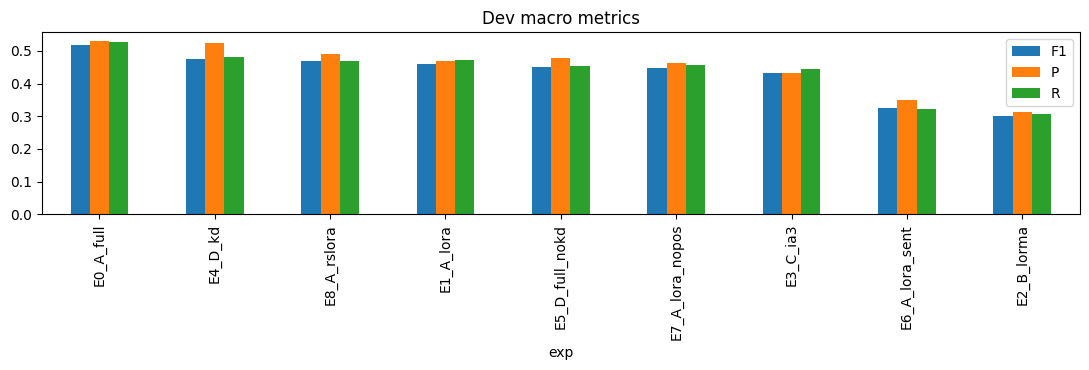

In [14]:
def collect():
    rows = []
    for f in sorted(glob.glob(f"{OUT_DIR}/*/result.json")):
        r = json.load(open(f)); d = r["dev"]
        rows.append({"exp": r["name"], "backbone": r["backbone"], "method": r["method"], "ctx": r["ctx"],
                     "F1": d["all"]["f1"], "P": d["all"]["precision"], "R": d["all"]["recall"],
                     "F1_CL": d["CL"]["f1"], "F1_IT": d["IT"]["f1"],
                     "params_M": r["total_params_M"], "trainable_M": r["trainable_params_M"], "train_%": r["trainable_pct"],
                     "train_min": r["train_min"], "peak_GB": r["peak_mem_gb"], "dev_infer_s": r["dev_infer_sec"]})
    return pd.DataFrame(rows).sort_values("F1", ascending=False)
RES = collect()
pd.set_option("display.width", 220); display(RES.round(4))
RES.to_csv(f"{WORK}/rr_results.csv", index=False)
ax = RES.set_index("exp")[["F1", "P", "R"]].plot.bar(figsize=(11, 3.8), title="Dev macro metrics"); plt.tight_layout(); plt.show()

In [15]:
R = RES.set_index("exp")
def g(e, c): return R.loc[e, c] if e in R.index else float("nan")
print("== PEFT vs full fine-tuning (A_decoder) ==")
for e in ["E0_A_full", "E1_A_lora", "E8_A_rslora"]:
    print(f"{e:14s} F1 {g(e,'F1'):.4f} | trainable {g(e,'trainable_M'):.2f}M ({g(e,'train_%'):.2f}%) | {g(e,'train_min'):.1f} min | {g(e,'peak_GB'):.1f} GB")
print("\n== Knowledge distillation ==")
for e in ["E0_A_full", "E4_D_kd", "E5_D_full_nokd"]:
    print(f"{e:16s} F1 {g(e,'F1'):.4f} | params {g(e,'params_M'):.1f}M | dev inference {g(e,'dev_infer_s'):.1f}s")
print(f"student/teacher: params x{g('E4_D_kd','params_M')/g('E0_A_full','params_M'):.2f} | speedup x{g('E0_A_full','dev_infer_s')/g('E4_D_kd','dev_infer_s'):.2f} | F1 retained {100*g('E4_D_kd','F1')/g('E0_A_full','F1'):.1f}%")
print("\n== Context ablation (A_decoder + LoRA) ==")
for e, lab in [("E6_A_lora_sent", "sentence only"), ("E7_A_lora_nopos", "doc context (no position)"), ("E1_A_lora", "doc context + position")]:
    print(f"{lab:28s} F1 {g(e,'F1'):.4f}")
print("\n== Domain gap (CL vs IT) ==")
print(RES[["exp", "F1_CL", "F1_IT"]].round(4).to_string(index=False))

== PEFT vs full fine-tuning (A_decoder) ==
E0_A_full      F1 0.5175 | trainable 110.34M (100.00%) | 4.8 min | 4.2 GB
E1_A_lora      F1 0.4588 | trainable 3.32M (2.94%) | 5.0 min | 2.9 GB
E8_A_rslora    F1 0.4693 | trainable 3.32M (2.94%) | 5.0 min | 2.9 GB

== Knowledge distillation ==
E0_A_full        F1 0.5175 | params 110.3M | dev inference 2.5s
E4_D_kd          F1 0.4759 | params 56.1M | dev inference 1.2s
E5_D_full_nokd   F1 0.4514 | params 56.1M | dev inference 1.2s
student/teacher: params x0.51 | speedup x2.10 | F1 retained 92.0%

== Context ablation (A_decoder + LoRA) ==
sentence only                F1 0.3246
doc context (no position)    F1 0.4464
doc context + position       F1 0.4588

== Domain gap (CL vs IT) ==
            exp  F1_CL  F1_IT
      E0_A_full 0.4165 0.5317
        E4_D_kd 0.3676 0.4878
    E8_A_rslora 0.3712 0.5550
      E1_A_lora 0.4303 0.4370
 E5_D_full_nokd 0.3696 0.4447
E7_A_lora_nopos 0.3945 0.4449
       E3_C_ia3 0.3238 0.4416
 E6_A_lora_sent 0.2412 0.395

analysing: E0_A_full


,F1_all,support_all,F1_CL,support_CL,F1_IT,support_IT
label,,,,,,
Fact,0.686,444,0.614,249,0.780,195
Issue,0.688,15,0.400,3,0.741,12
ArgumentPetitioner,0.411,400,0.417,344,0.379,56
ArgumentRespondent,0.484,272,0.510,236,0.281,36
Statute,0.797,120,0.793,58,0.800,62
Dissent,0.000,0,0.000,0,0.000,0
PrecedentReliedUpon,0.521,254,0.455,142,0.596,112
PrecedentNotReliedUpon,0.348,50,0.000,0,0.403,50
PrecedentOverruled,0.000,0,0.000,0,0.000,0


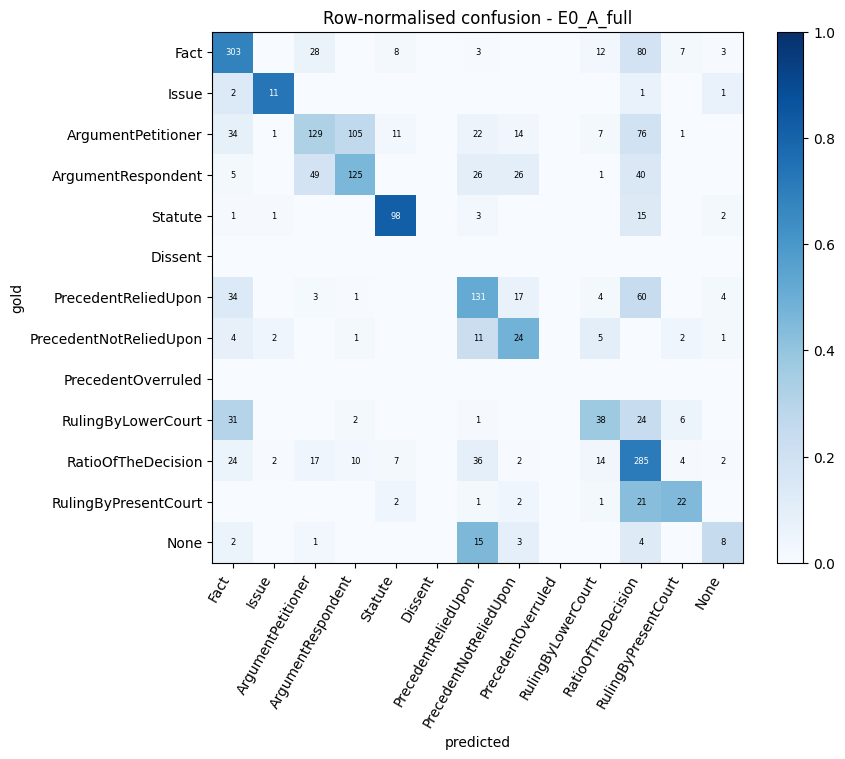

Top confusions (count, gold -> predicted):
    105  ArgumentPetitioner -> ArgumentRespondent
     80  Fact -> RatioOfTheDecision
     76  ArgumentPetitioner -> RatioOfTheDecision
     60  PrecedentReliedUpon -> RatioOfTheDecision
     49  ArgumentRespondent -> ArgumentPetitioner
     40  ArgumentRespondent -> RatioOfTheDecision
     36  RatioOfTheDecision -> PrecedentReliedUpon
     34  PrecedentReliedUpon -> Fact
     34  ArgumentPetitioner -> Fact
     31  RulingByLowerCourt -> Fact
     28  Fact -> ArgumentPetitioner
     26  ArgumentRespondent -> PrecedentReliedUpon
RatioOfTheDecision <-> RulingByPresentCourt: 4 / 21 mix-ups (gold RatioOfTheDecision / gold RulingByPresentCourt)
PrecedentReliedUpon <-> PrecedentNotReliedUpon: 17 / 11 mix-ups (gold PrecedentReliedUpon / gold PrecedentNotReliedUpon)
ArgumentPetitioner <-> ArgumentRespondent: 105 / 49 mix-ups (gold ArgumentPetitioner / gold ArgumentRespondent)
Fact <-> RulingByLowerCourt: 12 / 31 mix-ups (gold Fact / gold RulingByLower

In [16]:
def dev_arrays(name):
    lg = pickle.load(open(f"{OUT_DIR}/{name}/dev_logits.pkl", "rb"))
    _, yt, yp, dm = evaluate(dev_docs, lg); return yt, yp, dm

BEST = RES.iloc[0]["exp"]; print("analysing:", BEST)
yt, yp, dm = dev_arrays(BEST)
rows = []
for dom in ["all", "CL", "IT"]:
    msk = np.ones(len(yt), bool) if dom == "all" else dm == dom
    p, r, f, s = precision_recall_fscore_support(yt[msk], yp[msk], labels=range(len(LABELS)), zero_division=0)
    rows.append(pd.DataFrame({"label": LABELS, f"F1_{dom}": f, f"support_{dom}": s}).set_index("label"))
pcf = pd.concat(rows, axis=1); display(pcf.round(3))

cm = confusion_matrix(yt, yp, labels=range(len(LABELS)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(9, 7.5)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > .5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("gold"); plt.colorbar(im); plt.title(f"Row-normalised confusion - {BEST}"); plt.tight_layout(); plt.show()

conf = sorted([(cm[i, j], LABELS[i], LABELS[j]) for i in range(len(LABELS)) for j in range(len(LABELS)) if i != j and cm[i, j] > 0], reverse=True)[:12]
print("Top confusions (count, gold -> predicted):")
for c, a, b in conf: print(f"  {c:5d}  {a} -> {b}")

pairs = [("RatioOfTheDecision", "RulingByPresentCourt"), ("PrecedentReliedUpon", "PrecedentNotReliedUpon"),
         ("ArgumentPetitioner", "ArgumentRespondent"), ("Fact", "RulingByLowerCourt"), ("Issue", "Fact")]
for a, b in pairs:
    if a in L2I and b in L2I:
        i, j = L2I[a], L2I[b]; print(f"{a} <-> {b}: {cm[i, j]} / {cm[j, i]} mix-ups (gold {a} / gold {b})")

In [17]:
FINAL = ["E1_A_lora", "E2_B_lorma", "E3_C_ia3", "E4_D_kd"]     # A / B / C / D, four different techniques
if QUICK: FINAL = ["Q_" + f for f in FINAL]

# remove old zips/folders from earlier runs so only the correct files remain
for f in glob.glob(f"{SUB_DIR}/*"):
    shutil.rmtree(f) if os.path.isdir(f) else os.remove(f)
TMP = f"{WORK}/_zip_tmp"; shutil.rmtree(TMP, ignore_errors=True); os.makedirs(TMP)

cl_ids = {d["id"] for d in test_docs if d["domain"] == "CL"}
it_ids = {d["id"] for d in test_docs if d["domain"] == "IT"}
print("test docs: CL", len(cl_ids), "| IT", len(it_ids), "| CL/IT ID overlap:", len(cl_ids & it_ids))
assert not (cl_ids & it_ids), "CL and IT test IDs overlap - the official scorer cannot take one combined prediction.json; send me this output"

def check_zip(path):
    z = zipfile.ZipFile(path)
    assert z.namelist() == ["prediction.json"], z.namelist()                 # exact name, archive root, no folder
    p = json.loads(z.read("prediction.json")); exp = {d["id"]: d for d in test_docs}
    assert set(p) == set(exp), f"{len(set(exp) - set(p))} missing, {len(set(p) - set(exp))} unknown IDs"
    for k, v in p.items():
        assert isinstance(v, list) and len(v) == len(exp[k]["text"]), f"sentence-count mismatch in {k}"
        assert all(x in L2I for x in v), f"unknown label in {k}"
    print(f"  VALID: {os.path.basename(path)} | {len(p)} docs | {sum(len(v) for v in p.values())} sentences")

for n in FINAL:
    pred = json.load(open(f"{OUT_DIR}/{n}/test_pred.json"))                # keys are "CL::id" / "IT::id"
    merged = {k.split("::", 1)[1]: v for k, v in pred.items()}            # official IDs, CL + IT together
    json.dump(merged, open(f"{TMP}/prediction.json", "w"))
    zp = f"{SUB_DIR}/{n}.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(f"{TMP}/prediction.json", arcname="prediction.json")
    print(n); check_zip(zp)

shutil.rmtree(TMP, ignore_errors=True)
print("\nUpload these 4 files:", sorted(os.listdir(SUB_DIR)))

test docs: CL 5 | IT 5 | CL/IT ID overlap: 0
E1_A_lora
  VALID: E1_A_lora.zip | 10 docs | 2197 sentences
E2_B_lorma
  VALID: E2_B_lorma.zip | 10 docs | 2197 sentences
E3_C_ia3
  VALID: E3_C_ia3.zip | 10 docs | 2197 sentences
E4_D_kd
  VALID: E4_D_kd.zip | 10 docs | 2197 sentences

Upload these 4 files: ['E1_A_lora.zip', 'E2_B_lorma.zip', 'E3_C_ia3.zip', 'E4_D_kd.zip']


In [18]:
final = RES[RES["exp"].isin(FINAL)][["exp", "backbone", "method", "F1", "P", "R", "F1_CL", "F1_IT", "params_M", "trainable_M", "train_%", "train_min", "peak_GB"]]
display(final.round(4)); final.to_csv(f"{WORK}/rr_final_four.csv", index=False)
print(final.round(4).to_markdown(index=False) if hasattr(final, "to_markdown") else "")

,exp,backbone,method,F1,P,R,F1_CL,F1_IT,params_M,trainable_M,train_%,train_min,peak_GB
4,E4_D_kd,D_efficient,full+KD,0.4759,0.5245,0.4823,0.3676,0.4878,56.0706,56.0706,100.0000,3.7748,2.5511
1,E1_A_lora,A_decoder,lora,0.4588,0.4685,0.4714,0.4303,0.4370,112.8504,3.3205,2.9424,4.9563,2.9413
3,E3_C_ia3,C_hybrid,ia3,0.4319,0.4324,0.4454,0.3238,0.4416,115.1482,0.8691,0.7547,5.8496,3.8285
2,E2_B_lorma,B_encdec,lorma,0.3010,0.3126,0.3071,0.2846,0.2911,69.4384,2.3851,3.4348,4.1313,1.5547


| exp        | backbone    | method   |     F1 |      P |      R |   F1_CL |   F1_IT |   params_M |   trainable_M |   train_% |   train_min |   peak_GB |
|:-----------|:------------|:---------|-------:|-------:|-------:|--------:|--------:|-----------:|--------------:|----------:|------------:|----------:|
| E4_D_kd    | D_efficient | full+KD  | 0.4759 | 0.5245 | 0.4823 |  0.3676 |  0.4878 |    56.0706 |       56.0706 |  100      |      3.7748 |    2.5511 |
| E1_A_lora  | A_decoder   | lora     | 0.4588 | 0.4685 | 0.4714 |  0.4303 |  0.437  |   112.85   |        3.3205 |    2.9424 |      4.9563 |    2.9413 |
| E3_C_ia3   | C_hybrid    | ia3      | 0.4319 | 0.4324 | 0.4454 |  0.3238 |  0.4416 |   115.148  |        0.8691 |    0.7547 |      5.8496 |    3.8285 |
| E2_B_lorma | B_encdec    | lorma    | 0.301  | 0.3126 | 0.3071 |  0.2846 |  0.2911 |    69.4384 |        2.3851 |    3.4348 |      4.1313 |    1.5547 |


In [19]:
from sklearn.metrics import f1_score, precision_score, recall_score

def norm_id(i): return i[:-4] if i.endswith(".txt") else i

def official_eval(truth, pred, labels):
    truth = {norm_id(k): v for k, v in truth.items()}; pred = {norm_id(k): v for k, v in pred.items()}
    assert set(truth) == set(pred), f"ID mismatch: missing={len(set(truth)-set(pred))} extra={len(set(pred)-set(truth))}"
    allowed = set(labels); yt, yp = [], []
    for k in truth:
        assert len(truth[k]) == len(pred[k]), f"{k}: sentence-count mismatch"
        assert all(x in allowed for x in truth[k] + pred[k]), f"{k}: unknown label"
        yt += truth[k]; yp += pred[k]
    kw = dict(labels=labels, average="macro", zero_division=0)
    return dict(F1=f1_score(yt, yp, **kw), P=precision_score(yt, yp, **kw), R=recall_score(yt, yp, **kw), n_sent=len(yt))

dev_truth = {f"{d['domain']}::{d['id']}": d["labels"] for d in dev_docs}      # domain-prefixed => no CL/IT ID clash

def dev_pred_for(name):
    lg = pickle.load(open(f"{OUT_DIR}/{name}/dev_logits.pkl", "rb"))
    return {f"{d['domain']}::{d['id']}": [LABELS[i] for i in l.argmax(-1)] for d, l in zip(dev_docs, lg)}

rows = []
for f in sorted(glob.glob(f"{OUT_DIR}/*/result.json")):
    n = json.load(open(f))["name"]
    if not os.path.exists(f"{OUT_DIR}/{n}/dev_logits.pkl"): continue
    pr = dev_pred_for(n); o = official_eval(dev_truth, pr, LABELS)
    row = {"exp": n, "OFFICIAL_F1": o["F1"], "P": o["P"], "R": o["R"]}
    for dom in ("CL", "IT"):
        sel = [k for k in dev_truth if k.startswith(dom + "::")]
        oo = official_eval({k: dev_truth[k] for k in sel}, {k: pr[k] for k in sel}, LABELS)
        row[f"F1_{dom}"] = oo["F1"]
    rows.append(row)
OFF = pd.DataFrame(rows).sort_values("OFFICIAL_F1", ascending=False)
display(OFF.round(4)); OFF.to_csv(f"{WORK}/rr_official_dev_scores.csv", index=False)

# files for the REAL evaluate_phase3.py (only valid if dev IDs don't overlap between CL and IT)
BEST = OFF.iloc[0]["exp"]; pr = dev_pred_for(BEST)
cl_ids = {d["id"] for d in dev_docs if d["domain"] == "CL"}; it_ids = {d["id"] for d in dev_docs if d["domain"] == "IT"}
print("dev CL/IT ID overlap:", len(cl_ids & it_ids))
if not (cl_ids & it_ids):
    strip = lambda k: k.split("::", 1)[1]
    json.dump({strip(k): v for k, v in dev_truth.items() if k.startswith("CL::")}, open(f"{WORK}/cl_dev_truth.json", "w"))
    json.dump({strip(k): v for k, v in dev_truth.items() if k.startswith("IT::")}, open(f"{WORK}/it_dev_truth.json", "w"))
    json.dump({strip(k): v for k, v in pr.items()}, open(f"{WORK}/dev_prediction.json", "w"))
    json.dump(LABELS, open(f"{WORK}/labels.json", "w"))
    print("wrote cl_dev_truth.json, it_dev_truth.json, dev_prediction.json, labels.json")

,exp,OFFICIAL_F1,P,R,F1_CL,F1_IT
0,E0_A_full,0.4379,0.4486,0.4447,0.3524,0.4499
8,E8_A_rslora,0.4332,0.4538,0.4337,0.3426,0.4696
1,E1_A_lora,0.4235,0.4325,0.4351,0.3641,0.4034
7,E7_A_lora_nopos,0.4121,0.4271,0.4205,0.3338,0.4107
4,E4_D_kd,0.4027,0.4438,0.4081,0.3111,0.4128
3,E3_C_ia3,0.3987,0.3991,0.4112,0.2989,0.4076
5,E5_D_full_nokd,0.3820,0.4045,0.3828,0.3128,0.3763
6,E6_A_lora_sent,0.2996,0.3223,0.2967,0.2226,0.3342
2,E2_B_lorma,0.2547,0.2645,0.2599,0.2408,0.2463


dev CL/IT ID overlap: 0
wrote cl_dev_truth.json, it_dev_truth.json, dev_prediction.json, labels.json


In [20]:
def build_chunks(docs, ctx="doc", right_ctx=128):
    chunks = []
    for di, d in enumerate(docs):
        pre = DOM_PREFIX[d["domain"]] if USE_DOMAIN_TAG else [BOS_ID]
        sl = [x + [EOS_ID] for x in d["ids"]]; n = len(sl)
        if n == 0: continue
        lab = [L2I[y] for y in d["labels"]] if d["labels"] is not None else [-100] * n
        if ctx == "sent":
            for i in range(n):
                ids = pre + sl[i]
                chunks.append(dict(doc=di, ids=ids, spans=[(len(pre), len(ids), i, lab[i], bucket(i, n), True)]))
            continue
        budget = MAX_LEN - len(pre); i = 0
        while i < n:
            c0, ctok = i, 0
            while c0 > 0 and ctok + len(sl[c0 - 1]) <= CTX_TOKENS:
                c0 -= 1; ctok += len(sl[c0])
            cur, k = ctok, i
            while k < n and (k == i or cur + len(sl[k]) <= budget - right_ctx):
                cur += len(sl[k]); k += 1
            r1, rtok = k, 0
            while r1 < n and rtok + len(sl[r1]) <= right_ctx and cur + rtok + len(sl[r1]) <= budget:
                rtok += len(sl[r1]); r1 += 1
            ids, spans = list(pre), []
            for j in range(c0, r1):                        # ALL sentences get a span; only i<=j<k are scored
                s = len(ids); ids += sl[j]; sc = i <= j < k
                spans.append((s, len(ids), j, lab[j] if sc else -100, bucket(j, n), sc))
            chunks.append(dict(doc=di, ids=ids, spans=spans))
            i = k
    return chunks

def collate(batch):
    B = len(batch); L = max(len(c["ids"]) for c in batch); S = max(len(c["spans"]) for c in batch)
    ids = torch.full((B, L), PAD_ID, dtype=torch.long); mask = torch.zeros(B, L, dtype=torch.bool)
    st = torch.zeros(B, S, dtype=torch.long); en = torch.zeros(B, S, dtype=torch.long)
    y = torch.full((B, S), -100, dtype=torch.long); rel = torch.zeros(B, S, dtype=torch.long)
    sv = torch.zeros(B, S, dtype=torch.bool); pm = torch.zeros(B, S, dtype=torch.bool)
    meta = []
    for b, c in enumerate(batch):
        n = len(c["ids"]); ids[b, :n] = torch.tensor(c["ids"]); mask[b, :n] = True
        for s, (a, e, j, lb, rb, sc) in enumerate(c["spans"]):
            st[b, s], en[b, s], y[b, s], rel[b, s], pm[b, s], sv[b, s] = a, e, lb, rb, True, sc
        meta.append((c["doc"], [sp[2] if sp[5] else None for sp in c["spans"]]))
    return dict(ids=ids, mask=mask, st=st, en=en, y=y, rel=rel, sv=sv, pm=pm, meta=meta)

ch = build_chunks(train_docs, "doc", 128)
print(len(ch), "chunks | scored sentences:", sum(sp[5] for c in ch for sp in c["spans"]), "/", sum(len(d["text"]) for d in train_docs))

1100 chunks | scored sentences: 16845 / 16845


In [21]:
class RRModel(nn.Module):
    def __init__(self, name, backbone, n_labels, dim=768, use_pos=True, use_gru=True):
        super().__init__()
        self.name, self.bb, self.use_pos, self.use_gru = name, backbone, use_pos, use_gru
        self.pos = nn.Embedding(NB, 32)
        fdim = 2 * dim + (32 if use_pos else 0)
        self.head = nn.ModuleDict(dict(
            proj=nn.Sequential(nn.LayerNorm(fdim), nn.Dropout(0.1), nn.Linear(fdim, 512), nn.GELU()),
            gru=nn.GRU(512, 256, num_layers=2, batch_first=True, bidirectional=True, dropout=0.1) if use_gru else nn.Identity(),
            out=nn.Sequential(nn.Dropout(0.1), nn.Linear(512 + (512 if use_gru else 0), n_labels))))
    def _run(self, fn, *a):
        if GRAD_CKPT and self.training and torch.is_grad_enabled():
            return torch.utils.checkpoint.checkpoint(fn, *a, use_reentrant=False)
        return fn(*a)
    def hidden(self, ids, mask):
        bb = self.bb; x = bb.tok_emb(ids)
        if self.name == "B_encdec":
            am = mask[:, None, None, :]
            for blk in bb.enc: x = self._run(_enc_block, blk, x, am)
            return bb.norm_e(x)
        for blk in bb.blocks: x = self._run(blk, x)
        return bb.norm_f(x)
    def forward(self, b):
        h = self.hidden(b["ids"], b["mask"]).float(); D = h.size(-1)
        cs = F.pad(torch.cumsum(h, 1), (0, 0, 1, 0))
        st, en = b["st"], b["en"]
        gi = lambda ix: ix.unsqueeze(-1).expand(-1, -1, D)
        mean = (cs.gather(1, gi(en)) - cs.gather(1, gi(st))) / (en - st).clamp(min=1).unsqueeze(-1)
        last = h.gather(1, gi((en - 1).clamp(min=0)))
        feats = [mean, last] + ([self.pos(b["rel"])] if self.use_pos else [])
        x = self.head["proj"](torch.cat(feats, -1))                       # (B,S,512)
        if self.use_gru:                                                   # bidirectional context across the chunk's sentences
            lens = b["pm"].sum(1).clamp(min=1).cpu()
            pk = nn.utils.rnn.pack_padded_sequence(x, lens, batch_first=True, enforce_sorted=False)
            o, _ = self.head["gru"](pk)
            o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=x.size(1))
            x = torch.cat([x, o.to(x.dtype)], -1)
        return self.head["out"](x)

def build_rr(cfg):
    name = cfg["backbone"]; bb = load_phase1(name)
    if name == "B_encdec":
        for a in ("dec", "norm_f", "head"): delattr(bb, a)
    else:
        del bb.head
    if cfg.get("keep_layers"): bb.blocks = nn.ModuleList(list(bb.blocks)[:cfg["keep_layers"]])
    model = RRModel(name, bb, len(LABELS), use_pos=cfg.get("use_pos", True), use_gru=cfg.get("use_gru", True))
    if cfg["method"] != "full":
        for p in bb.parameters(): p.requires_grad = False
        n = apply_peft(bb, cfg["method"], cfg.get("rank", 16), cfg.get("alpha", 32), cfg.get("lora_dropout", 0.05))
        assert n > 0, "no layers adapted"
        if cfg.get("train_norm"):                                          # also tune RMSNorm gains (tiny, helps adaptation)
            for m in bb.modules():
                if isinstance(m, RMSNorm):
                    for p in m.parameters(): p.requires_grad = True
    return model.to(DEVICE)

In [22]:
@torch.no_grad()
def predict_logits(model, docs, ctx, right_ctx, bs):
    chunks = sorted(build_chunks(docs, ctx, right_ctx), key=lambda c: len(c["ids"]))
    model.eval()
    out = [np.zeros((len(d["text"]), len(LABELS)), np.float32) for d in docs]
    seen = [np.zeros(len(d["text"]), bool) for d in docs]
    for b in DataLoader(chunks, batch_size=bs, shuffle=False, collate_fn=collate):
        bd = to_dev(b)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            lg = model(bd).float().cpu().numpy()
        for bi, (doc, sents) in enumerate(b["meta"]):
            for si, s in enumerate(sents):
                if s is None: continue                                     # unscored context slot
                out[doc][s] = lg[bi, si]; seen[doc][s] = True
    assert all(s.all() for s in seen), "some sentences were not scored"
    return out

def evaluate(docs, logits):
    yt, yp, dm = [], [], []
    for d, lg in zip(docs, logits):
        yt += [L2I[y] for y in d["labels"]]; yp += lg.argmax(-1).tolist(); dm += [d["domain"]] * len(lg)
    yt, yp, dm = np.array(yt), np.array(yp), np.array(dm)
    def m(mask):
        p, r, f, _ = precision_recall_fscore_support(yt[mask], yp[mask], labels=list(range(len(LABELS))), average="macro", zero_division=0)
        return dict(f1=float(f), precision=float(p), recall=float(r), acc=float((yt[mask] == yp[mask]).mean()))
    res = {"all": m(np.ones(len(yt), bool))}
    for dom in sorted(set(dm)): res[dom] = m(dm == dom)
    return res, yt, yp, dm

In [23]:
EPOCHS = 6                                   # lower to 5 if time is tight
V2 = {
 "V2_E0_A_full":  dict(name="V2_E0_A_full",  backbone="A_decoder",   method="full",  lr=5e-5, right_ctx=128),
 "V2_E1_A_lora":  dict(name="V2_E1_A_lora",  backbone="A_decoder",   method="lora",  rank=32, alpha=64, lr=6e-4, right_ctx=128, train_norm=True),
 "V2_E2_B_lorma": dict(name="V2_E2_B_lorma", backbone="B_encdec",    method="lorma", rank=32, alpha=64, lr=6e-4, right_ctx=128, train_norm=True),
 "V2_E3_C_ia3":   dict(name="V2_E3_C_ia3",   backbone="C_hybrid",    method="ia3",   lr=5e-3, right_ctx=128, train_norm=True),
 "V2_E4_D_kd":    dict(name="V2_E4_D_kd",    backbone="D_efficient", method="full",  lr=1e-4, keep_layers=6, right_ctx=128,
                       kd=dict(teacher="V2_E0_A_full", T=2.0, alpha=0.5)),
 "V2_E5_D_nokd":  dict(name="V2_E5_D_nokd",  backbone="D_efficient", method="full",  lr=1e-4, keep_layers=6, right_ctx=128),   # KD control
}
ALL_CFG.update(V2); print(list(V2))

['V2_E0_A_full', 'V2_E1_A_lora', 'V2_E2_B_lorma', 'V2_E3_C_ia3', 'V2_E4_D_kd', 'V2_E5_D_nokd']


In [24]:
v0 = run_experiment(V2["V2_E0_A_full"])
v1 = run_experiment(V2["V2_E1_A_lora"])
v2 = run_experiment(V2["V2_E2_B_lorma"])
v3 = run_experiment(V2["V2_E3_C_ia3"])
v4 = run_experiment(V2["V2_E4_D_kd"])
v5 = run_experiment(V2["V2_E5_D_nokd"])        # optional control

V2_E0_A_full ep1/6:   0%|          | 0/275 [00:00<?, ?it/s]

[V2_E0_A_full] ep1 loss 1.7574 | dev macro-F1 0.3350 (CL 0.2791 | IT 0.3460) P 0.3648 R 0.3795 | 1.5 min


V2_E0_A_full ep2/6:   0%|          | 0/275 [00:00<?, ?it/s]

[V2_E0_A_full] ep2 loss 0.9916 | dev macro-F1 0.3695 (CL 0.3040 | IT 0.3804) P 0.3852 R 0.4138 | 2.9 min


V2_E0_A_full ep3/6:   0%|          | 0/275 [00:00<?, ?it/s]

[V2_E0_A_full] ep3 loss 0.6222 | dev macro-F1 0.4136 (CL 0.3446 | IT 0.4307) P 0.4132 R 0.4319 | 4.4 min


... (62 outputs left out)

V2_E5_D_nokd ep5/6:   0%|          | 0/275 [00:00<?, ?it/s]

[V2_E5_D_nokd] ep5 loss 0.2543 | dev macro-F1 0.3915 (CL 0.2982 | IT 0.4350) P 0.4189 R 0.4007 | 3.6 min


V2_E5_D_nokd ep6/6:   0%|          | 0/275 [00:00<?, ?it/s]

[V2_E5_D_nokd] ep6 loss 0.1242 | dev macro-F1 0.3898 (CL 0.2893 | IT 0.4256) P 0.4322 R 0.3935 | 4.4 min
[V2_E5_D_nokd] BEST dev macro-F1 0.3915 @ epoch 5


In [25]:
def build_chunks(docs, ctx="doc", right_ctx=128, jitter=False):
    chunks = []
    for di, d in enumerate(docs):
        pre = DOM_PREFIX[d["domain"]] if USE_DOMAIN_TAG else [BOS_ID]
        sl = [x + [EOS_ID] for x in d["ids"]]; n = len(sl)
        if n == 0: continue
        lab = [L2I[y] for y in d["labels"]] if d["labels"] is not None else [-100] * n
        if ctx == "sent":
            for i in range(n):
                ids = pre + sl[i]
                chunks.append(dict(doc=di, ids=ids, spans=[(len(pre), len(ids), i, lab[i], bucket(i, n), True)]))
            continue
        budget = MAX_LEN - len(pre); i = 0
        cap = random.randint(1, 25) if jitter else 10 ** 9; first = True       # random size of the first chunk shifts all boundaries
        while i < n:
            c0, ctok = i, 0
            while c0 > 0 and ctok + len(sl[c0 - 1]) <= CTX_TOKENS:
                c0 -= 1; ctok += len(sl[c0])
            cur, k = ctok, i
            while k < n and (k == i or cur + len(sl[k]) <= budget - right_ctx) and (not first or k - i < cap):
                cur += len(sl[k]); k += 1
            r1, rtok = k, 0
            while r1 < n and rtok + len(sl[r1]) <= right_ctx and cur + rtok + len(sl[r1]) <= budget:
                rtok += len(sl[r1]); r1 += 1
            ids, spans = list(pre), []
            for j in range(c0, r1):
                s = len(ids); ids += sl[j]; sc = i <= j < k
                spans.append((s, len(ids), j, lab[j] if sc else -100, bucket(j, n), sc))
            chunks.append(dict(doc=di, ids=ids, spans=spans))
            i = k; first = False
    return chunks
    

In [26]:
from sklearn.metrics import f1_score
K = len(LABELS)
def lsm(x):
    x = x - x.max(-1, keepdims=True); return x - np.log(np.exp(x).sum(-1, keepdims=True))

cnt_t, cnt_s, cnt_u = np.full((K, K), 1.0), np.full(K, 1.0), np.full(K, 1.0)      # label transition / start / prior statistics from TRAIN
for d in train_docs:
    y = [L2I[l] for l in d["labels"]]
    if not y: continue
    cnt_s[y[0]] += 1
    for a in y: cnt_u[a] += 1
    for a, b in zip(y[:-1], y[1:]): cnt_t[a, b] += 1
LOG_T = np.log(cnt_t / cnt_t.sum(1, keepdims=True)); LOG_S = np.log(cnt_s / cnt_s.sum()); LOG_PRIOR = np.log(cnt_u / cnt_u.sum())

def viterbi(lp, beta):
    n = len(lp)
    if n == 0: return []
    dp = lp[0] + beta * LOG_S; bp = np.zeros((n, K), int)
    for t in range(1, n):
        sc = dp[:, None] + beta * LOG_T
        bp[t] = sc.argmax(0); dp = sc.max(0) + lp[t]
    path = [int(dp.argmax())]
    for t in range(n - 1, 0, -1): path.append(int(bp[t][path[-1]]))
    return path[::-1]

def load_lp(names, split):
    out = None
    for n in names:
        L = [lsm(x) for x in pickle.load(open(f"{OUT_DIR}/{n}/{split}_logits.pkl", "rb"))]
        out = L if out is None else [a + b for a, b in zip(out, L)]
    return [x / len(names) for x in out]

def decode(lps, alpha, beta): return [viterbi(lp - alpha * LOG_PRIOR, beta) for lp in lps]
def f1_of(docs, paths):
    yt = [L2I[l] for d in docs for l in d["labels"]]; yp = [i for p in paths for i in p]
    return f1_score(yt, yp, labels=list(range(K)), average="macro", zero_division=0)

GRID = [(a, b) for a in (0.0, 0.5, 1.0) for b in (0.0, 0.25, 0.5, 1.0, 1.5)]
def tune(names):
    lps = load_lp(names, "dev"); raw = f1_of(dev_docs, decode(lps, 0, 0))
    best = max((f1_of(dev_docs, decode(lps, a, b)), a, b) for a, b in GRID)
    return raw, best

avail = [n for n in sorted(os.listdir(OUT_DIR)) if os.path.exists(f"{OUT_DIR}/{n}/test_logits.pkl") and not n.startswith("Q_")]
rows = []
for n in avail:
    raw, (f, a, b) = tune([n]); rows.append(dict(exp=n, raw_F1=raw, viterbi_F1=f, alpha=a, beta=b))
PP = pd.DataFrame(rows).sort_values("viterbi_F1", ascending=False).reset_index(drop=True)
print("== single models (official 13-label macro-F1 on dev) =="); display(PP.round(4))

# ---- ensembles of the top-N models ----
ranked = PP["exp"].tolist(); ens = []
for N in range(2, min(6, len(ranked)) + 1):
    raw, (f, a, b) = tune(ranked[:N]); ens.append((f, N, a, b, raw)); print(f"ensemble top-{N}: raw {raw:.4f} -> viterbi {f:.4f} (alpha {a}, beta {b})")

# ---- write final zips ----
FINAL_DIR = f"{WORK}/submissions_final"; shutil.rmtree(FINAL_DIR, ignore_errors=True); os.makedirs(FINAL_DIR)
def write_zip(tag, names, alpha, beta):
    paths = decode(load_lp(names, "test"), alpha, beta)
    pred = {d["id"]: [LABELS[i] for i in p] for d, p in zip(test_docs, paths)}
    tmp = f"{WORK}/_zip_tmp"; os.makedirs(tmp, exist_ok=True); json.dump(pred, open(f"{tmp}/prediction.json", "w"))
    zp = f"{FINAL_DIR}/{tag}.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{tmp}/prediction.json", arcname="prediction.json")
    z = zipfile.ZipFile(zp); assert z.namelist() == ["prediction.json"]
    p = json.loads(z.read("prediction.json")); exp = {d["id"]: d for d in test_docs}
    assert set(p) == set(exp) and all(len(p[k]) == len(exp[k]["text"]) and all(x in L2I for x in p[k]) for k in p)
    print(f"  VALID {tag}.zip | {len(p)} docs")

MAIN = {"A_decoder": ["E1_A_lora", "V2_E1_A_lora"], "B_encdec": ["E2_B_lorma", "V2_E2_B_lorma"],
        "C_hybrid": ["E3_C_ia3", "V2_E3_C_ia3"],   "D_efficient": ["E4_D_kd", "V2_E4_D_kd"]}
P = PP.set_index("exp")
for bb, cands in MAIN.items():
    c = [x for x in cands if x in P.index]
    if not c: print("no results for", bb); continue
    pick = max(c, key=lambda x: P.loc[x, "viterbi_F1"])
    print(f"{bb}: {pick} | dev F1 {P.loc[pick,'raw_F1']:.4f} -> {P.loc[pick,'viterbi_F1']:.4f}")
    write_zip(f"{pick}_vit", [pick], P.loc[pick, "alpha"], P.loc[pick, "beta"])
if ens:
    f, N, a, b, raw = max(ens); print(f"ENSEMBLE top-{N} dev F1 {f:.4f}"); write_zip("ENSEMBLE_extra", ranked[:N], a, b)
print("\nfiles:", sorted(os.listdir(FINAL_DIR)))

== single models (official 13-label macro-F1 on dev) ==


,exp,raw_F1,viterbi_F1,alpha,beta
0,V2_E1_A_lora,0.4428,0.4632,1.0,1.50
1,E0_A_full,0.4379,0.4590,0.0,0.25
2,E8_A_rslora,0.4332,0.4555,1.0,1.00
3,E1_A_lora,0.4235,0.4470,0.0,0.50
4,E7_A_lora_nopos,0.4121,0.4469,0.5,1.00
5,V2_E0_A_full,0.4180,0.4406,1.0,0.25
6,V2_E3_C_ia3,0.4244,0.4405,0.0,0.25
7,E4_D_kd,0.4027,0.4208,0.5,0.50
8,E5_D_full_nokd,0.3820,0.4138,0.5,1.00
9,E3_C_ia3,0.3987,0.4133,0.0,0.50


ensemble top-2: raw 0.4451 -> viterbi 0.4699 (alpha 0.5, beta 0.5)
ensemble top-3: raw 0.4507 -> viterbi 0.4644 (alpha 1.0, beta 1.0)
ensemble top-4: raw 0.4500 -> viterbi 0.4697 (alpha 1.0, beta 1.0)
ensemble top-5: raw 0.4577 -> viterbi 0.4654 (alpha 0.5, beta 0.25)
ensemble top-6: raw 0.4558 -> viterbi 0.4736 (alpha 0.5, beta 0.25)
A_decoder: V2_E1_A_lora | dev F1 0.4428 -> 0.4632
  VALID V2_E1_A_lora_vit.zip | 10 docs
B_encdec: V2_E2_B_lorma | dev F1 0.3133 -> 0.3317
  VALID V2_E2_B_lorma_vit.zip | 10 docs
C_hybrid: V2_E3_C_ia3 | dev F1 0.4244 -> 0.4405
  VALID V2_E3_C_ia3_vit.zip | 10 docs
D_efficient: E4_D_kd | dev F1 0.4027 -> 0.4208
  VALID E4_D_kd_vit.zip | 10 docs
ENSEMBLE top-6 dev F1 0.4736
  VALID ENSEMBLE_extra.zip | 10 docs

files: ['E4_D_kd_vit.zip', 'ENSEMBLE_extra.zip', 'V2_E1_A_lora_vit.zip', 'V2_E2_B_lorma_vit.zip', 'V2_E3_C_ia3_vit.zip']
